# Self-RAG Step 4: Answer Support Verification (IsSUP)

![Self-RAG Pipeline with Answer Reflection.png](<attachment:Self-RAG Pipeline with Answer Reflection.png>)

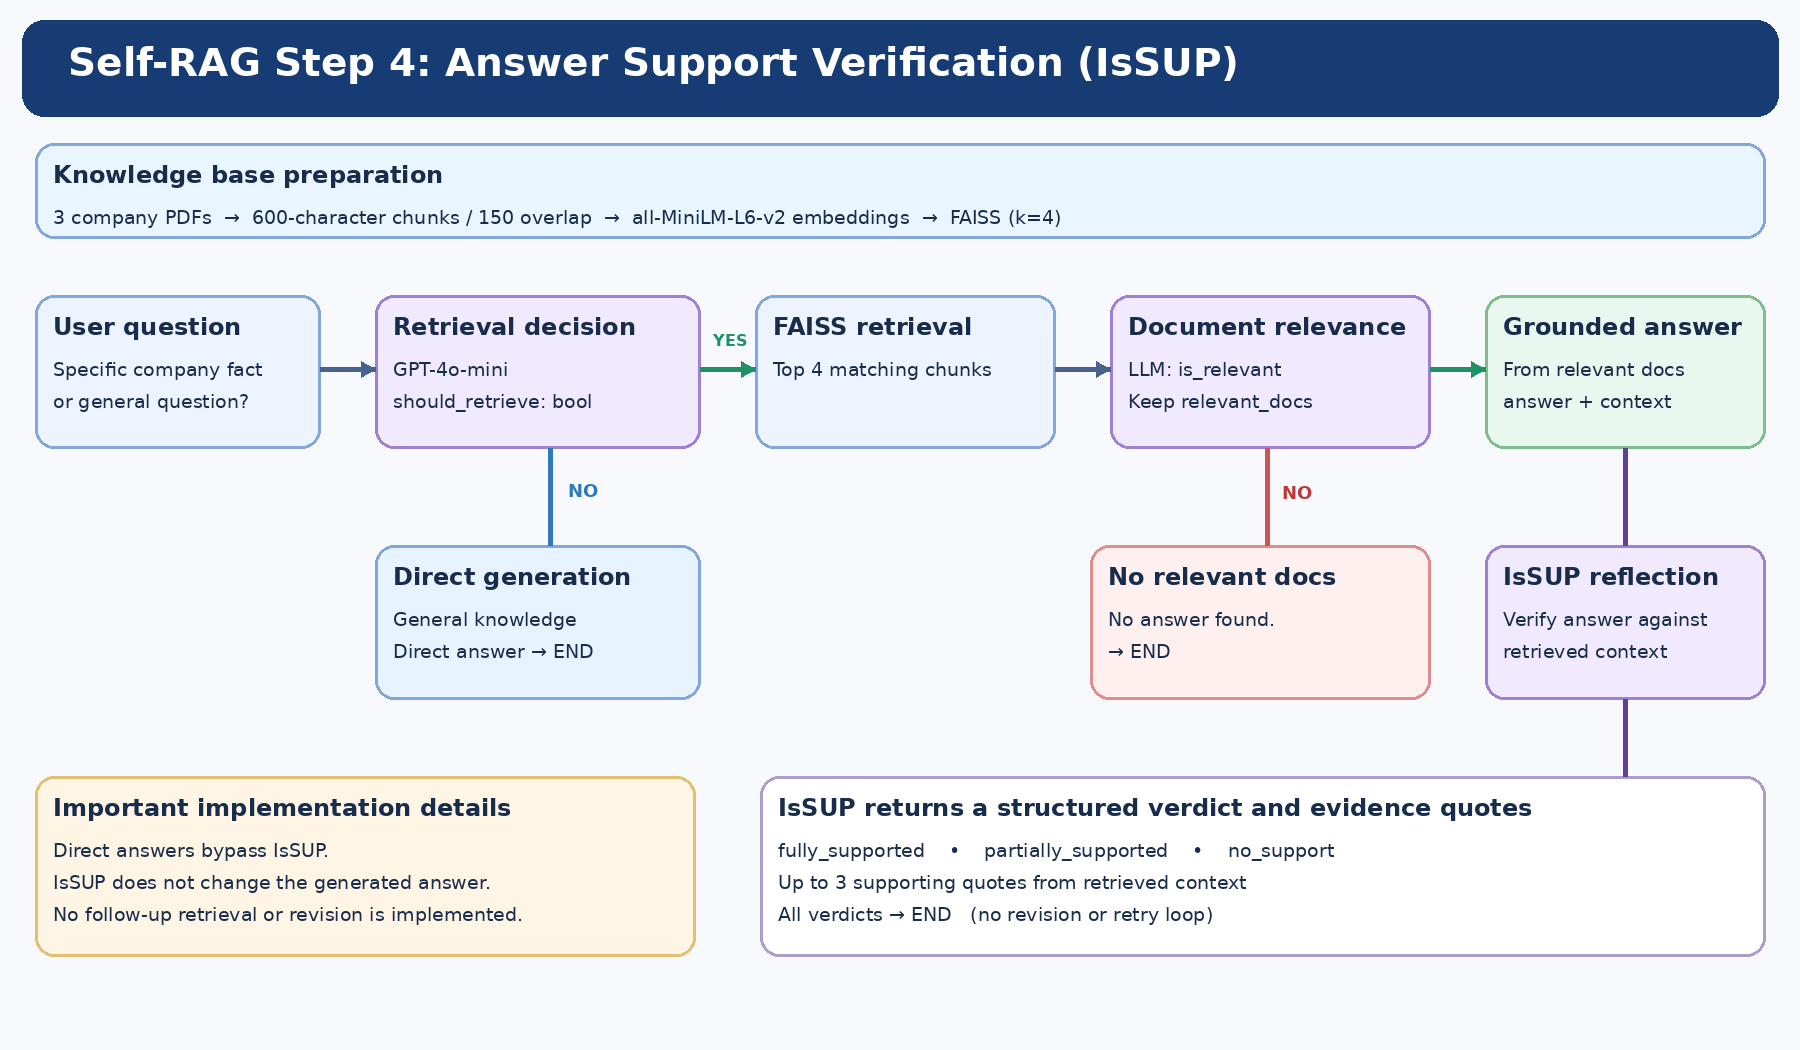
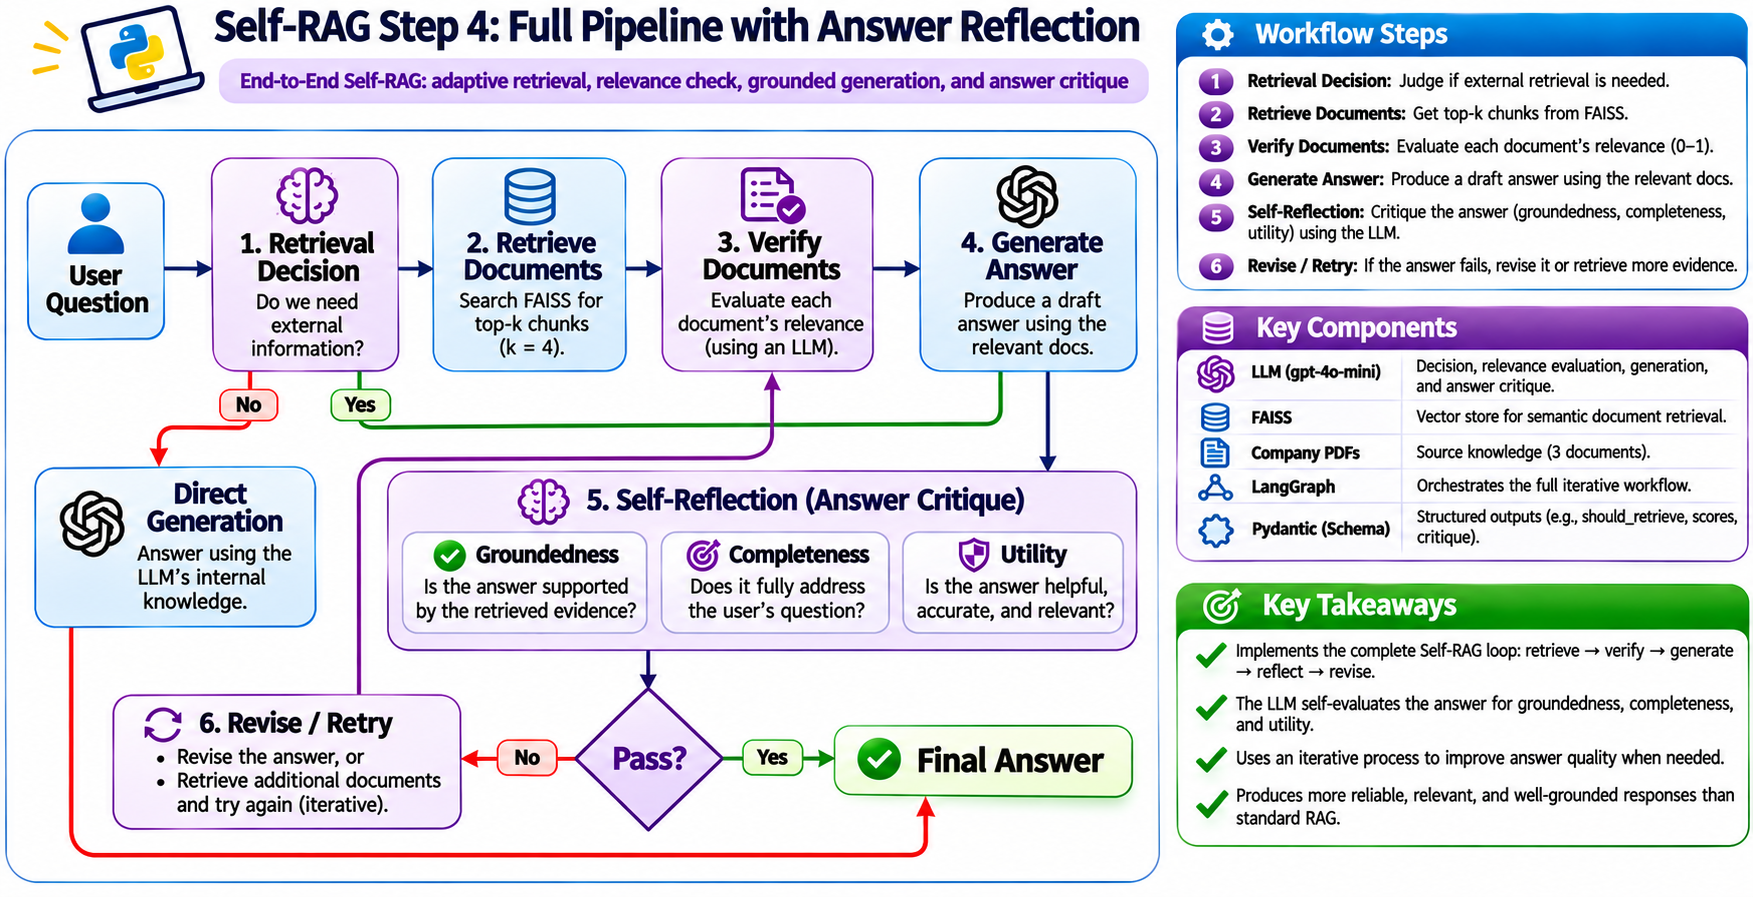


This notebook extends Self-RAG Step 3 by introducing **post-generation evidence verification** using LangGraph, FAISS, and GPT-4o-mini.

### 1. Knowledge Base

- Load three company PDFs using `PyPDFLoader`.
- Split documents into chunks (`chunk_size=600`, `chunk_overlap=150`).
- Generate embeddings using `all-MiniLM-L6-v2`.
- Store chunks in FAISS and retrieve the top 4 matches.

### 2. Adaptive Retrieval and Generation

- **Retrieval decision:** Determine whether external information is required.
- **Relevance evaluation:** Filter retrieved chunks using an LLM.
- **Grounded generation:** Generate an answer using relevant document context.
- **Fallback:** Return `"No answer found."` if no relevant documents remain.

### 3. Answer Support Verification (New)

The `is_sup()` node evaluates whether the generated answer is supported by the retrieved context.

```python
class IsSUPDecision(BaseModel):
    issup: Literal[
        "fully_supported",
        "partially_supported",
        "no_support"
    ]
    evidence: List[str] = Field(default_factory=list)
```

The evaluator returns:

| Verdict | Meaning |
|---|---|
| `fully_supported` | All meaningful claims are supported. |
| `partially_supported` | Core facts are supported, but some interpretation is unsupported. |
| `no_support` | Key claims lack supporting evidence. |

It also extracts up to three supporting quotations.

### 4. LangGraph Workflow

```text
START → decide_retrieval
               │
        ┌──────┴──────┐
        ▼             ▼
   generate_direct  retrieve
        │             │
       END       is_relevant
                      │
              Relevant docs?
                /        \
              Yes         No
               │           │
      generate_from_    no_answer_found
         context           │
               │          END
             is_sup
               │
              END
```

### 5. Key Takeaway

**Step 4 introduces answer-level self-reflection by checking whether generated claims are supported by retrieved evidence.**

Unlike Step 3, the system now returns a structured support verdict and evidence quotations.

**Current limitation:** IsSUP evaluates the answer but does not automatically revise it. Direct answers also bypass support verification. The next improvement is conditional routing based on the IsSUP verdict.

In [6]:
import os
from typing import List, TypedDict, Literal
from pydantic import BaseModel, Field

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv

# Load API credentials and configuration from the project .env file.
load_dotenv()

api_key = os.getenv("OPENAI_API_KEY")
base_url = os.getenv("BASE_URL")

In [7]:
# Set False to rebuild the FAISS index from the source PDFs; True loads the saved index.
faiss_saved = True

# Build and save the index when no reusable local index is selected.
if faiss_saved==False:
    # Load the company policy, profile, and pricing PDFs as LangChain Documents.
    docs = (
        PyPDFLoader("./documents/DSwithBappy_Company_Policies.pdf").load()
        + PyPDFLoader("./documents/DSwithBappy_Company_Profile.pdf").load()
        + PyPDFLoader("./documents/DSwithBappy_Product_and_Pricing.pdf").load()

    )
    # Split long documents into overlapping passages for retrieval.
    chunks = RecursiveCharacterTextSplitter(
    chunk_size=600, chunk_overlap=150
    ).split_documents(docs)
    # Create the sentence-transformer encoder used for document and query vectors.
    hf_embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')
    # Embed the chunks and build a FAISS similarity-search index.
    vector_store = FAISS.from_documents(chunks, hf_embeddings)
    # Configure retrieval to return the four nearest chunks per query.
    retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})
    
else:
    # Create the sentence-transformer encoder used for document and query vectors.
    hf_embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')
    # Restore the saved FAISS index; only load an index you trust.
    vector_store = FAISS.load_local("faiss_index", hf_embeddings, allow_dangerous_deserialization=True)
    # Configure retrieval to return the four nearest chunks per query.
    retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})


In [8]:
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0, api_key=api_key, base_url=base_url)

In [9]:
# -----------------------------
# Graph State
# -----------------------------
class State(TypedDict):
    question: str
    need_retrieval: bool
    docs: List[Document]
    relevant_docs: List[Document]
    context: str
    answer: str

    # Post-generation verification
    issup: Literal["fully_supported", "partially_supported", "no_support"]
    evidence: List[str]

In [10]:
# -----------------------------
# 1) Decide retrieval
# -----------------------------
class RetrieveDecision(BaseModel):
    should_retrieve: bool = Field(
        ...,
        description="True if external documents are needed to answer reliably, else False."
    )

decide_retrieval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You decide whether retrieval is needed.\n"
            "Return JSON with key: should_retrieve (boolean).\n\n"
            "Guidelines:\n"
            "- should_retrieve=True if answering requires specific facts from company documents.\n"
            "- should_retrieve=False for general explanations/definitions.\n"
            "- If unsure, choose True."
        ),
        ("human", "Question: {question}"),
    ]
)

# Constrain the model response to the retrieval decision schema.
should_retrieve_llm = llm.with_structured_output(RetrieveDecision)

def decide_retrieval(state: State):
    # Decide whether this question needs facts from the local documents.
    decision: RetrieveDecision = should_retrieve_llm.invoke(
        decide_retrieval_prompt.format_messages(question=state["question"])
    )
    # Store the retrieval decision in the graph state for routing.
    return {"need_retrieval": decision.should_retrieve}

# Select direct answering or retrieval based on the decision in state.
def route_after_decide(state: State) -> Literal["generate_direct", "retrieve"]:
    return "retrieve" if state["need_retrieval"] else "generate_direct"


In [11]:
# -----------------------------
# 2) Direct answer (no retrieval)
# -----------------------------
direct_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Answer using only your general knowledge.\n"
            "If it requires specific company info, say:\n"
            "'I don't know based on my general knowledge.'"
        ),
        ("human", "{question}"),
    ]
)

# Answer general questions without consulting the document collection.
def generate_direct(state: State):
    out = llm.invoke(direct_generation_prompt.format_messages(question=state["question"]))
    return {"answer": out.content}


In [12]:
# -----------------------------
# 3) Retrieve
# -----------------------------
def retrieve(state: State):
    # Save retrieved document chunks in graph state.
    return {"docs": retriever.invoke(state["question"])}


In [13]:
# -----------------------------
# 4) Relevance filter 
# -----------------------------
class RelevanceDecision(BaseModel):
    is_relevant: bool = Field(
        ...,
        description="True ONLY if the document contains info that can directly answer the question."
    )

is_relevant_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are judging document relevance at a TOPIC level.\n"
            "Return JSON matching the schema.\n\n"
            "A document is relevant if it discusses the same entity or topic area as the question.\n"
            "It does NOT need to contain the exact answer.\n\n"
            "Examples:\n"
            "- HR policies are relevant to questions about notice period, probation, termination, benefits.\n"
            "- Pricing documents are relevant to questions about refunds, trials, billing terms.\n"
            "- Company profile is relevant to questions about leadership, culture, size, or strategy.\n\n"
            "Do NOT decide whether the document fully answers the question.\n"
            "That will be checked later by IsSUP.\n"
            "When unsure, return is_relevant=true."
        ),
        ("human", "Question:\n{question}\n\nDocument:\n{document}"),
    ]
)


# Return a validated relevance decision instead of free-form text.
relevance_llm = llm.with_structured_output(RelevanceDecision)

def is_relevant(state: State):
    relevant_docs: List[Document] = []
    # Safely evaluate retrieved chunks, including when the state has none.
    for doc in state.get("docs", []):
        decision: RelevanceDecision = relevance_llm.invoke(
            is_relevant_prompt.format_messages(
                question=state["question"],
                document=doc.page_content,
            )
        )
        # Keep only documents the model considers useful evidence.
        if decision.is_relevant:
            relevant_docs.append(doc)
    # Pass the filtered evidence to the next graph node.
    return {"relevant_docs": relevant_docs}

# Continue to grounded generation only when relevant evidence remains.
def route_after_relevance(state: State) -> Literal["generate_from_context", "no_answer_found"]:
    if state.get("relevant_docs") and len(state["relevant_docs"]) > 0:
        return "generate_from_context"
    return "no_answer_found"


In [14]:
# -----------------------------
# 5) Generate from context
# -----------------------------
rag_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a business rag chatbot.\n\n"
            "You will receive a CONTEXT block from internal company documents.\n"
            "Task:\n"
            "Answer the question based on the context"
            "Dont mention that you are getting a context in your answer"
        ),
        ("human", "Question:\n{question}\n\nContext:\n{context}"),
    ]
)

def generate_from_context(state: State):
    # Combine relevant document chunks into the context supplied to the LLM.
    context = "\n\n---\n\n".join([d.page_content for d in state.get("relevant_docs", [])]).strip()
    # Avoid generating a context-based answer when there is no evidence.
    if not context:
        return {"answer": "No answer found.", "context": ""}
    out = llm.invoke(
        rag_generation_prompt.format_messages(question=state["question"], context=context)
    )
    return {"answer": out.content, "context": context}

def no_answer_found(state: State):
    return {"answer": "No answer found.", "context": ""}


In [15]:
# -----------------------------
# 6) IsSUP verify + revise loop
# -----------------------------
class IsSUPDecision(BaseModel):
    issup: Literal["fully_supported", "partially_supported", "no_support"]
    evidence: List[str] = Field(default_factory=list)

issup_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are verifying whether the ANSWER is supported by the CONTEXT.\n"
            "Return JSON with keys: issup, evidence.\n"
            "issup must be one of: fully_supported, partially_supported, no_support.\n\n"
            "How to decide issup:\n"
            "- fully_supported:\n"
            "  Every meaningful claim is explicitly supported by CONTEXT, and the ANSWER does NOT introduce\n"
            "  any qualitative/interpretive words that are not present in CONTEXT.\n"
            "  (Examples of disallowed words unless present in CONTEXT: culture, generous, robust, designed to,\n"
            "  supports professional development, best-in-class, employee-first, etc.)\n\n"
            "- partially_supported:\n"
            "  The core facts are supported, BUT the ANSWER includes ANY abstraction, interpretation, or qualitative\n"
            "  phrasing not explicitly stated in CONTEXT (e.g., calling policies 'culture', saying leave is 'generous',\n"
            "  or inferring outcomes like 'supports professional development').\n\n"
            "- no_support:\n"
            "  The key claims are not supported by CONTEXT.\n\n"
            "Rules:\n"
            "- Be strict: if you see ANY unsupported qualitative/interpretive phrasing, choose partially_supported.\n"
            "- If the answer is mostly unrelated to the question or unsupported, choose no_support.\n"
            "- Evidence: include up to 3 short direct quotes from CONTEXT that support the supported parts.\n"
            "- Do not use outside knowledge."
        ),
        (
            "human",
            "Question:\n{question}\n\n"
            "Answer:\n{answer}\n\n"
            "Context:\n{context}\n"
        ),
    ]
)



# Require a structured support verdict and evidence quotes.
issup_llm = llm.with_structured_output(IsSUPDecision)

# Verify generated claims against the retrieved context.
def is_sup(state: State):
    decision: IsSUPDecision = issup_llm.invoke(
        issup_prompt.format_messages(
            question=state["question"],
            answer=state.get("answer", ""),
            context=state.get("context", ""),
        )
    )
    return {"issup": decision.issup, "evidence": decision.evidence}


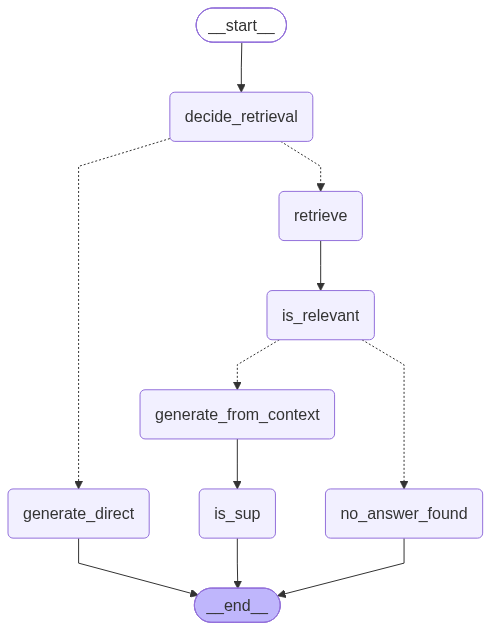

In [16]:
# -----------------------------
# Build graph
# -----------------------------
g = StateGraph(State)

g.add_node("decide_retrieval", decide_retrieval)
g.add_node("generate_direct", generate_direct)
g.add_node("retrieve", retrieve)

g.add_node("is_relevant", is_relevant)
g.add_node("generate_from_context", generate_from_context)
g.add_node("no_answer_found", no_answer_found)

g.add_node("is_sup", is_sup)

# Set the first node that runs when the graph is invoked.
g.add_edge(START, "decide_retrieval")

# Add a decision-based branch in the workflow.
g.add_conditional_edges(
    "decide_retrieval",
    route_after_decide,
    {"generate_direct": "generate_direct", "retrieve": "retrieve"},
)

g.add_edge("generate_direct", END)

g.add_edge("retrieve", "is_relevant")

# Add a decision-based branch in the workflow.
g.add_conditional_edges(
    "is_relevant",
    route_after_relevance,
    {"generate_from_context": "generate_from_context", "no_answer_found": "no_answer_found"},
)

# If no answer found, end
g.add_edge("no_answer_found", END)

# If generated from context, verify with IsSUP loop
g.add_edge("generate_from_context", "is_sup")
g.add_edge("is_sup", END)

# Compile the nodes and edges into an executable graph.
app = g.compile()
app


In [18]:
# Run the complete Self-RAG workflow for the supplied state.
result = app.invoke(
        {
            "question": 'Describe DSwtihBappy company culture',
            "docs": [],
            "relevant_docs": [],
            "context": "",
            "answer": "",
            "issup": "",
            "evidence": [],
        },
    )

print("need_retrieval:", result.get("need_retrieval"))
print("#docs:", len(result.get("docs", [])))
print("#relevant_docs:", len(result.get("relevant_docs", [])))
print("issup:", result.get("issup"))
print("evidence:", result.get("evidence"))
print("answer:", result.get("answer"))

need_retrieval: True
#docs: 4
#relevant_docs: 3
issup: partially_supported
evidence: ['DSwithBappy is committed to maintaining a fair, inclusive, collaborative, and performance-driven workplace.', 'All employment and team decisions are made fairly and without discrimination.', 'Team members are encouraged to maintain a healthy work-life balance.']
answer: The company culture at DSwithBappy is centered around inclusivity, collaboration, and a strong focus on practical learning in the field of artificial intelligence. The organization promotes a fair and equal opportunity workplace, ensuring that all employment decisions are made without discrimination. 

Team members are encouraged to engage in a performance-driven environment, supported by bi-annual performance and growth reviews that help in career and skill progression. The culture emphasizes respect and safety, with strict anti-harassment policies in place to maintain a respectful workplace.

Additionally, DSwithBappy values work-li

In [ ]:
# How many employees does DSwtihBappy have?
# Describe DSwtihBappy's company culture.
# Do DSwtihBappy plans include a free trial? If yes, how many days?